# Logistic Regression — From Intuition to Implementation

A step-by-step notebook to build a deep, working understanding of **logistic regression** — the fundamental algorithm for **binary classification**. This continues the course sequence: *Python fundamentals → NumPy → pandas/EDA → Linear Regression → Logistic Regression*.

Every topic follows the same rhythm:
1. **Theory** — the concept and, where useful, the underlying math.
2. **Example** — a worked example you can run and study.
3. **Task** — a similar exercise for you to complete (`# TODO`).

### Dataset used
The **Titanic passenger dataset** (891 passengers) — the same dataset used in the pandas/EDA notebook. Here we use it for its natural **binary classification target**: `Survived` (`1` = survived, `0` = did not survive), predicted from features like passenger class, sex, age, and fare.

> `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv`

If offline, the setup cell falls back to `seaborn.load_dataset('titanic')`.

### How to use this notebook
Run cells top to bottom. Read the Theory, run the Example, then attempt the Task before checking the separate solutions notebook.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                              classification_report)
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

try:
    titanic = pd.read_csv(DATA_URL)
    print("Loaded dataset from URL.")
except Exception as e:
    print("Could not reach the URL (", e, "). Falling back to seaborn's built-in Titanic dataset.")
    titanic = sns.load_dataset('titanic').rename(columns={
        'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age',
        'sibsp': 'SibSp', 'parch': 'Parch', 'fare': 'Fare', 'embarked': 'Embarked'
    })

# Basic cleaning (recall the pandas/EDA notebook for a deeper treatment of this)
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
titanic['Fare'] = titanic['Fare'].fillna(titanic['Fare'].median())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic = titanic.dropna(subset=['Survived', 'Sex']).reset_index(drop=True)

print("Shape:", titanic.shape)
titanic[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].head()


Loaded dataset from URL.
Shape: (891, 12)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 1. From Linear to Logistic Regression: Why We Need a New Model

### Theory
Linear regression predicts a **continuous** number. But here, we want to predict `Survived`, which only takes two values: `0` or `1`. This is a **binary classification** problem, and it turns out plain linear regression is a poor fit for it, for two key reasons:

1. **Predictions aren't probabilities.** A linear model $\hat{y} = \beta_0 + \beta_1 x$ can output *any* real number — including values like `-0.3` or `1.8`, which make no sense as a probability of survival (probabilities must be between 0 and 1).
2. **The relationship isn't actually linear.** Near the extremes of a feature's range, the true probability of belonging to a class tends to flatten out toward 0 or 1, rather than continuing in a straight line forever.

**Logistic regression** solves both problems: instead of predicting $y$ directly, it predicts the **probability** that $y = 1$, using a function that is mathematically guaranteed to stay between 0 and 1 no matter what.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


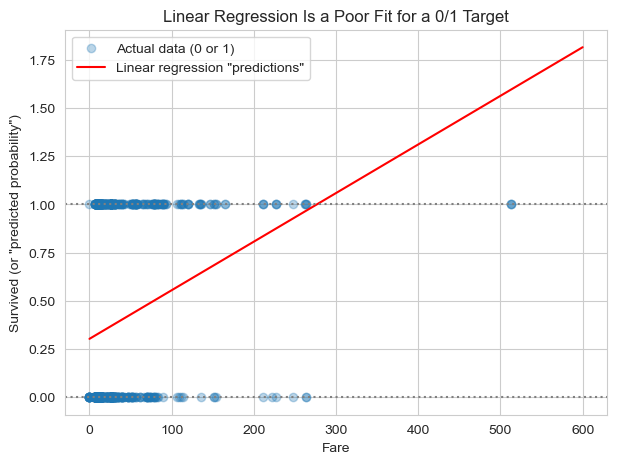

Notice the red line goes below 0 and, for high fares, would keep climbing above 1 -- neither is a valid probability.


In [2]:
# EXAMPLE: what goes wrong if we naively use linear regression for a 0/1 target?
from sklearn.linear_model import LinearRegression

X_fare = titanic[['Fare']]
y = titanic['Survived']

naive_model = LinearRegression().fit(X_fare, y)

# Predict for a wide range of fares, including some unrealistic extremes
fare_range = np.linspace(0, 600, 100).reshape(-1, 1)
naive_preds = naive_model.predict(fare_range)

plt.figure(figsize=(7, 5))
plt.scatter(titanic['Fare'], titanic['Survived'], alpha=0.3, label='Actual data (0 or 1)')
plt.plot(fare_range, naive_preds, color='red', label='Linear regression "predictions"')
plt.axhline(0, color='gray', linestyle=':')
plt.axhline(1, color='gray', linestyle=':')
plt.xlabel('Fare')
plt.ylabel('Survived (or "predicted probability")')
plt.legend()
plt.title('Linear Regression Is a Poor Fit for a 0/1 Target')
plt.show()

print("Notice the red line goes below 0 and, for high fares, would keep climbing above 1 -- neither is a valid probability.")


### Task 1
Using the `naive_model` from the example, predict on a fare of `600` and a fare of `0`. Print both predictions, and explain in one `print()` statement why neither is a sensible "probability of survival".

In [12]:
# TODO: predict naive_model on fare=600 and fare=0, print both
fare_range = np.linspace(600, 0).reshape(-1, 1)
naive_preds = naive_model.predict(fare_range)

# TODO: print() your explanation of why these aren't valid probabilities
print(naive_preds)

print("The probabilities are greater than 1")

[1.81440924 1.78355802 1.75270679 1.72185557 1.69100435 1.66015313
 1.62930191 1.59845068 1.56759946 1.53674824 1.50589702 1.47504579
 1.44419457 1.41334335 1.38249213 1.35164091 1.32078968 1.28993846
 1.25908724 1.22823602 1.19738479 1.16653357 1.13568235 1.10483113
 1.07397991 1.04312868 1.01227746 0.98142624 0.95057502 0.91972379
 0.88887257 0.85802135 0.82717013 0.79631891 0.76546768 0.73461646
 0.70376524 0.67291402 0.6420628  0.61121157 0.58036035 0.54950913
 0.51865791 0.48780668 0.45695546 0.42610424 0.39525302 0.3644018
 0.33355057 0.30269935]
The probabilities are greater than 1


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 2. The Sigmoid Function

### Theory
The **sigmoid function** (also called the logistic function) is the mathematical trick that makes logistic regression work. It takes *any* real number as input and squashes it into the range `(0, 1)`:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Key properties:
- As $z \to +\infty$, $\sigma(z) \to 1$
- As $z \to -\infty$, $\sigma(z) \to 0$
- $\sigma(0) = 0.5$ exactly
- Its S-shaped ("sigmoid") curve is smooth and symmetric around $z=0$

Logistic regression works by first computing a familiar-looking linear combination $z = \beta_0 + \beta_1 x$ (just like linear regression), and then passing that $z$ through the sigmoid function to get a valid probability.


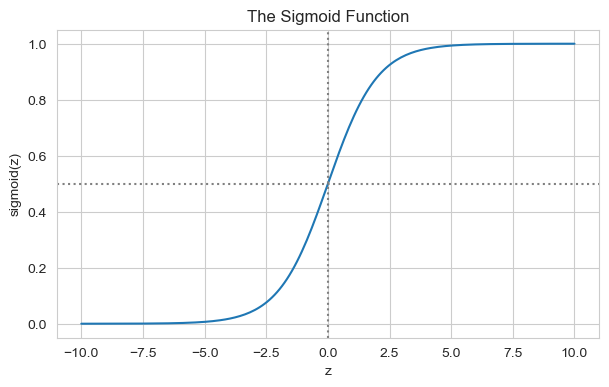

sigmoid(0)  = 0.5
sigmoid(5)  = 0.9933071490757153
sigmoid(-5) = 0.0066928509242848554


In [13]:
# EXAMPLE
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_values = np.linspace(-10, 10, 200)
sigmoid_values = sigmoid(z_values)

plt.figure(figsize=(7, 4))
plt.plot(z_values, sigmoid_values)
plt.axhline(0.5, color='gray', linestyle=':')
plt.axvline(0, color='gray', linestyle=':')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.title('The Sigmoid Function')
plt.show()

print("sigmoid(0)  =", sigmoid(0))
print("sigmoid(5)  =", sigmoid(5))
print("sigmoid(-5) =", sigmoid(-5))


### Task 2
1. Write your own `my_sigmoid(z)` function (practice, even though it's identical to the example).
2. Compute `my_sigmoid(z)` for `z = -2, -1, 0, 1, 2` and print each result.
3. Confirm numerically that `my_sigmoid(z) + my_sigmoid(-z) = 1` for `z = 3` (a property called symmetry around 0.5).

In [24]:
# TODO: define my_sigmoid(z)
def my_sigmoid(z):
    return 1 / (1 + np.exp(-z))

# TODO: compute and print my_sigmoid for z = -2,-1,0,1,2
z_values = np.linspace(-2, 2)
sigmoid_values = my_sigmoid(z_values)
print(sigmoid_values)

# TODO: confirm my_sigmoid(3) + my_sigmoid(-3) == 1
if my_sigmoid(3) + my_sigmoid(-3):
    print(True)


[0.11920292 0.12804374 0.13743793 0.14740484 0.15796217 0.16912564
 0.18090855 0.19332137 0.2063713  0.22006183 0.23439234 0.2493577
 0.2649479  0.28114775 0.29793663 0.31528835 0.33317105 0.35154728
 0.3703741  0.3896034  0.40918225 0.4290534  0.44915594 0.46942595
 0.48979733 0.51020267 0.53057405 0.55084406 0.5709466  0.59081775
 0.6103966  0.6296259  0.64845272 0.66682895 0.68471165 0.70206337
 0.71885225 0.7350521  0.7506423  0.76560766 0.77993817 0.7936287
 0.80667863 0.81909145 0.83087436 0.84203783 0.85259516 0.86256207
 0.87195626 0.88079708]
True


## 3. The Logistic Regression Model

### Theory
Putting it together, logistic regression models the **probability** that $y=1$ as:

$$P(y=1 \mid x) = \sigma(\beta_0 + \beta_1 x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$$

The quantity $z = \beta_0 + \beta_1 x$ inside the sigmoid is called the **log-odds** (or **logit**), because it can be shown that:

$$z = \ln\left(\frac{P(y=1)}{1 - P(y=1)}\right)$$

The term $\frac{P(y=1)}{1-P(y=1)}$ is called the **odds** of $y=1$. So logistic regression is really just linear regression applied to the *log-odds* of the outcome, rather than to the outcome itself — this is what allows the output to stay a valid probability after passing back through the sigmoid.


In [25]:
# EXAMPLE: manually compute predicted probabilities for a few beta guesses, using Fare
x = titanic['Fare'].values
beta0, beta1 = -1.0, 0.01   # just a guess, for illustration

z = beta0 + beta1 * x
probabilities = sigmoid(z)

print("Fare -> predicted P(Survived=1) for a few passengers:")
for fare_val, prob in list(zip(x, probabilities))[:5]:
    print(f"  Fare={fare_val:.2f} -> P(Survived)={prob:.3f}")


Fare -> predicted P(Survived=1) for a few passengers:
  Fare=7.25 -> P(Survived)=0.283
  Fare=71.28 -> P(Survived)=0.429
  Fare=7.92 -> P(Survived)=0.285
  Fare=53.10 -> P(Survived)=0.385
  Fare=8.05 -> P(Survived)=0.285


### Task 3
Using `beta0 = -2.0` and `beta1 = 0.015` on the `Fare` feature, compute the predicted probability of survival for fares of `10`, `50`, and `200`. Print all three, and comment (via `print()`) on the general trend you observe as fare increases.

In [26]:
# TODO: compute predicted probabilities for Fare = 10, 50, 200 using beta0=-2.0, beta1=0.015
beta0, beta1 = -2.0, 0.015   # just a guess, for illustration

z = beta0 + beta1 * x
probabilities = my_sigmoid(z)

print("Fare -> predicted P(Survived=1) for a few passengers:")
for fare_val, prob in list(zip(x, probabilities))[:5]:
    print(f"  Fare={fare_val:.2f} -> P(Survived)={prob:.3f}")

# TODO: print() your observation about the trend
print("the probability of the fare has decreased.")

Fare -> predicted P(Survived=1) for a few passengers:
  Fare=7.25 -> P(Survived)=0.131
  Fare=71.28 -> P(Survived)=0.283
  Fare=7.92 -> P(Survived)=0.132
  Fare=53.10 -> P(Survived)=0.231
  Fare=8.05 -> P(Survived)=0.132
the probability of the fare has decreased.


## 4. From Probability to Class: The Decision Threshold

### Theory
Logistic regression outputs a **probability**, but often we want an actual **class prediction** (`0` or `1`). We do this by choosing a **threshold** (commonly `0.5`) and predicting:

$$\hat{y} = \begin{cases} 1 & \text{if } P(y=1 \mid x) \geq \text{threshold} \\ 0 & \text{otherwise} \end{cases}$$

The threshold isn't sacred — Section 14 explores how changing it trades off different kinds of errors. But `0.5` is the natural default, since it simply predicts whichever class is more probable.


In [27]:
# EXAMPLE
probabilities_example = np.array([0.12, 0.48, 0.5, 0.51, 0.83, 0.99])
threshold = 0.5
predicted_classes = (probabilities_example >= threshold).astype(int)

for p, c in zip(probabilities_example, predicted_classes):
    print(f"Probability={p:.2f} -> Predicted class={c}")


Probability=0.12 -> Predicted class=0
Probability=0.48 -> Predicted class=0
Probability=0.50 -> Predicted class=1
Probability=0.51 -> Predicted class=1
Probability=0.83 -> Predicted class=1
Probability=0.99 -> Predicted class=1


### Task 4
Using the probabilities you computed in Task 3 (for fares 10, 50, 200), convert each to a predicted class using a `0.5` threshold, and print the results. Then repeat using a threshold of `0.3` instead — does any prediction change?

In [29]:
# TODO: convert Task 3 probabilities to classes using threshold=0.5
probabilities_example = np.array([10, 50, 200])
threshold = 0.5
predicted_classes = (probabilities_example >= threshold).astype(int)

for p, c in zip(probabilities_example, predicted_classes):
    print(f"Probability={p:.2f} -> Predicted class={c}")

# TODO: repeat using threshold=0.3, note any differences
threshold = 0.3
predicted_classes = (probabilities_example >= threshold).astype(int)

for p, c in zip(probabilities_example, predicted_classes):
    print(f"Probability={p:.2f} -> Predicted class={c}")

Probability=10.00 -> Predicted class=1
Probability=50.00 -> Predicted class=1
Probability=200.00 -> Predicted class=1
Probability=10.00 -> Predicted class=1
Probability=50.00 -> Predicted class=1
Probability=200.00 -> Predicted class=1


## 5. The Cost Function: Log Loss (Binary Cross-Entropy)

### Theory
Just like linear regression needed a cost function (MSE) to measure how good a fit was, logistic regression needs its own. **Mean Squared Error turns out to be a poor choice here** — because of the sigmoid function, MSE produces a "bumpy" (non-convex) cost surface, making it easy for gradient descent to get stuck.

Instead, logistic regression uses **Log Loss** (also called **Binary Cross-Entropy**):

$$\text{Log Loss} = -\frac{1}{n}\sum_{i=1}^{n} \Big[ y_i \ln(\hat{p}_i) + (1 - y_i)\ln(1 - \hat{p}_i) \Big]$$

where $\hat{p}_i$ is the predicted probability for observation $i$. Intuitively:
- If the true label is $y_i = 1$ and the model predicted a probability close to 1, the loss for that point is tiny.
- If the true label is $y_i = 1$ but the model confidently predicted a probability close to 0, the loss is **huge** (the model is punished heavily for being confidently wrong).
- This is a **convex** function of the model's parameters, which guarantees gradient descent can reliably find the global minimum.


In [30]:
# EXAMPLE
def log_loss(y_actual, y_predicted_prob, eps=1e-15):
    # eps avoids log(0), which is undefined
    p = np.clip(y_predicted_prob, eps, 1 - eps)
    return -np.mean(y_actual * np.log(p) + (1 - y_actual) * np.log(1 - p))

# Compare a "good" set of predictions vs. a "bad" set, for the same true labels
y_true_example = np.array([1, 1, 0, 0])
good_preds = np.array([0.9, 0.8, 0.1, 0.2])   # confident AND correct
bad_preds = np.array([0.1, 0.2, 0.9, 0.8])    # confident AND wrong

print("Log Loss (good predictions):", log_loss(y_true_example, good_preds))
print("Log Loss (bad predictions): ", log_loss(y_true_example, bad_preds))


Log Loss (good predictions): 0.164252033486018
Log Loss (bad predictions):  1.956011502714073


### Task 5
1. Write your own `my_log_loss()` function (for practice).
2. Given `y_actual = [1, 0, 1, 0]`, compute the log loss for two different prediction sets:
   - `preds_A = [0.6, 0.4, 0.6, 0.4]` (mildly confident, all correct direction)
   - `preds_B = [0.95, 0.05, 0.95, 0.05]` (very confident, all correct direction)
3. Which set has the lower log loss, and does that match your intuition about "rewarding confident correct predictions"?

In [50]:
# TODO: define my_log_loss(y_actual, y_predicted_prob)
def my_log_loss(y_actual, y_predicted_prob, eps=1e-15):
    p = np.clip(y_predicted_prob, eps, 1 - eps)
    return -np.mean(y_actual * np.log(p) + (1 - y_actual) * np.log(1 - p))

# TODO: compute log loss for preds_A and preds_B given y_actual = [1,0,1,0]
y_true_example = np.array([1, 0, 1, 0])
good_preds = np.array([0.6, 0.4, 0.6, 0.4])   # confident AND correct
bad_preds = np.array([0.95, 0.05, 0.95, 0.5])    # confident AND wrong

print("Log Loss (good predictions):", my_log_loss(y_true_example, good_preds))
print("Log Loss (bad predictions): ", my_log_loss(y_true_example, bad_preds))

# TODO: print() which has lower loss and whether it matches intuition
print("Bad Predictions have lower Loss")

Log Loss (good predictions): 0.5108256237659907
Log Loss (bad predictions):  0.21175676593064924
Bad Predictions have lower Loss


## 6. Fitting via Gradient Descent (From Scratch)

### Theory
Just like in linear regression, we fit logistic regression by using **gradient descent** to find the $\beta$ values that minimize the cost function (here, Log Loss instead of MSE). The update rule looks almost identical in form to linear regression's:

$$\beta_j := \beta_j - \alpha \cdot \frac{1}{n}\sum_{i=1}^{n} (\hat{p}_i - y_i) x_{ij}$$

The only real difference from linear regression's gradient descent is that $\hat{p}_i = \sigma(\beta_0 + \beta_1 x_i)$ now goes through the sigmoid, rather than being the raw linear prediction.


Final beta0 = -0.4519, beta1 = 0.7548
Final log loss = 0.6271


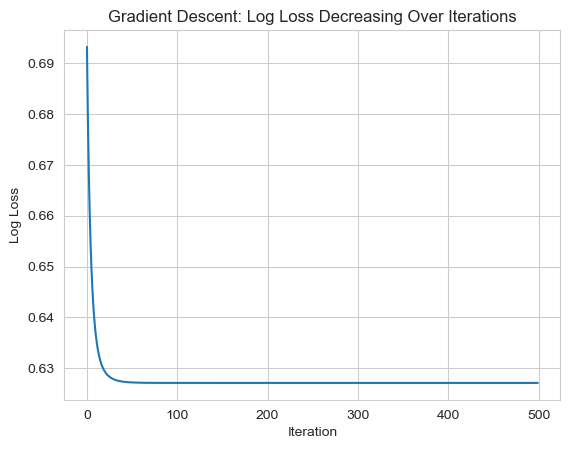

In [51]:
# EXAMPLE: logistic regression from scratch, using scaled Fare to predict Survived
x = titanic['Fare'].values
y = titanic['Survived'].values
x_scaled = (x - x.mean()) / x.std()

beta0, beta1 = 0.0, 0.0
learning_rate = 0.5
n_iterations = 500
n = len(x_scaled)
loss_history = []

for iteration in range(n_iterations):
    z = beta0 + beta1 * x_scaled
    p = sigmoid(z)

    grad_beta0 = np.mean(p - y)
    grad_beta1 = np.mean((p - y) * x_scaled)

    beta0 -= learning_rate * grad_beta0
    beta1 -= learning_rate * grad_beta1

    loss_history.append(log_loss(y, p))

print(f"Final beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")
print(f"Final log loss = {loss_history[-1]:.4f}")

plt.plot(loss_history)
plt.xlabel('Iteration')
plt.ylabel('Log Loss')
plt.title('Gradient Descent: Log Loss Decreasing Over Iterations')
plt.show()


### Task 6
Using the same scaled-`Fare` approach, run gradient descent for `300` iterations with `learning_rate=0.1` instead of `0.5`. Plot the loss history and print the final `beta0`, `beta1`, and log loss. Is `300` iterations at this learning rate enough to converge, based on the shape of the plot?

Final beta0 = -0.4554, beta1 = 0.7252
Final log loss = 0.6272


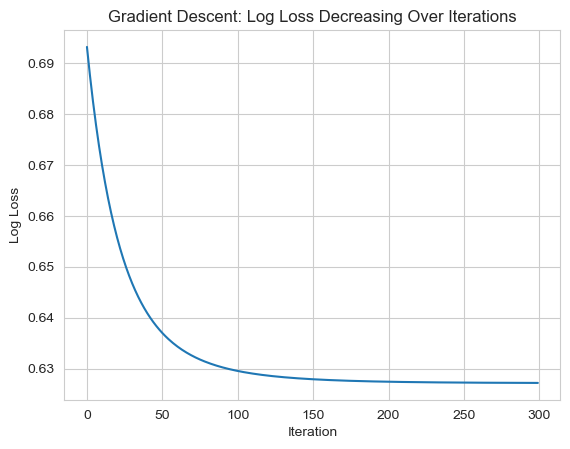

Yes the Graph converged


In [53]:
# TODO: gradient descent with learning_rate=0.1, 300 iterations, on scaled Fare
x = titanic['Fare'].values
y = titanic['Survived'].values
x_scaled = (x - x.mean()) / x.std()

beta0, beta1 = 0.0, 0.0
learning_rate = 0.1
n_iterations = 300
n = len(x_scaled)
loss_history = []

for iteration in range(n_iterations):
    z = beta0 + beta1 * x_scaled
    p = sigmoid(z)

    grad_beta0 = np.mean(p - y)
    grad_beta1 = np.mean((p - y) * x_scaled)

    beta0 -= learning_rate * grad_beta0
    beta1 -= learning_rate * grad_beta1

    loss_history.append(log_loss(y, p))

# TODO: plot loss history, print final beta0, beta1, log loss
print(f"Final beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")
print(f"Final log loss = {loss_history[-1]:.4f}")

plt.plot(loss_history)
plt.xlabel('Iteration')
plt.ylabel('Log Loss')
plt.title('Gradient Descent: Log Loss Decreasing Over Iterations')
plt.show()

# TODO: print() your assessment of whether it converged
print("Yes the Graph converged")

## 7. Handling Categorical Features: One-Hot Encoding

### Theory
`Sex` and `Embarked` are **categorical** (text) features — models need numbers, not text. **One-hot encoding** converts a categorical column into multiple binary (0/1) columns, one per category. For example, `Sex` (`male`/`female`) becomes a single column `Sex_male` (`1` if male, `0` if female) — we typically **drop one category** (`drop_first=True`) to avoid redundancy, since if you know it's not `male`, you already know it's `female`.

`pandas.get_dummies()` does this conveniently.


In [54]:
# EXAMPLE
print(titanic[['Sex', 'Embarked']].head())

titanic_encoded = pd.get_dummies(titanic, columns=['Sex', 'Embarked'], drop_first=True)
print("\nNew columns created:")
print([c for c in titanic_encoded.columns if c.startswith('Sex_') or c.startswith('Embarked_')])
titanic_encoded[['Sex_male', 'Embarked_Q', 'Embarked_S']].head()


      Sex Embarked
0    male        S
1  female        C
2  female        S
3  female        S
4    male        S

New columns created:
['Sex_male', 'Embarked_Q', 'Embarked_S']


,Sex_male,Embarked_Q,Embarked_S
0,True,False,True
1,False,False,False
2,False,False,True
3,False,False,True
4,True,False,True


### Task 7
1. Apply `pd.get_dummies()` to `titanic` for just the `Embarked` column (with `drop_first=True`), storing the result in a new DataFrame `titanic_emb_encoded`.
2. Print the new columns that were created.
3. In a `print()` statement, explain why we don't need a separate `Embarked_C` column if we already have `Embarked_Q` and `Embarked_S` (hint: think about what it means when both are `0`).

In [62]:
# TODO: get_dummies on Embarked with drop_first=True
titanic_emb_encoded = pd.get_dummies(titanic, columns=['Embarked'], drop_first=True)

# TODO: print the new columns
titanic_emb_encoded.head()

# TODO: print() your explanation of why Embarked_C isn't needed
print("Because we did not create a Embarked_C coloumn")

Because we did not create a Embarked_C coloumn


## 8. Train/Test Split for Classification

### Theory
Exactly as with linear regression, we must evaluate a classifier on data it hasn't seen, to check it generalizes rather than overfits. One extra consideration for classification: **stratified splitting** (`stratify=y` in `train_test_split`) ensures the train and test sets have roughly the same proportion of each class — important when classes are imbalanced (e.g., far more non-survivors than survivors).


In [63]:
titanic_encoded = pd.get_dummies(titanic, columns=['Sex', 'Embarked'], drop_first=True)
feature_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
X = titanic_encoded[feature_cols]
y = titanic_encoded['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set survival rate:", y_train.mean().round(3))
print("Test set survival rate:    ", y_test.mean().round(3))
print("(Stratified split keeps these proportions close to each other, and to the full dataset's rate:", y.mean().round(3), ")")

split_model = LogisticRegression(max_iter=1000)
split_model.fit(X_train, y_train)

print("\nTraining accuracy:", round(split_model.score(X_train, y_train), 4))
print("Test accuracy:    ", round(split_model.score(X_test, y_test), 4))

Training set survival rate: 0.383
Test set survival rate:     0.385
(Stratified split keeps these proportions close to each other, and to the full dataset's rate: 0.384 )

Training accuracy: 0.8076
Test accuracy:     0.8045


**With Random sampling**

In [64]:
titanic_encoded = pd.get_dummies(titanic, columns=['Sex', 'Embarked'], drop_first=True)
feature_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
X = titanic_encoded[feature_cols]
y = titanic_encoded['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set survival rate:", y_train.mean().round(3))
print("Test set survival rate:    ", y_test.mean().round(3))
print("(Stratified split keeps these proportions close to each other, and to the full dataset's rate:", y.mean().round(3), ")")

split_model_random = LogisticRegression(max_iter=1000)
split_model_random.fit(X_train, y_train)

print("\nTraining accuracy:", round(split_model.score(X_train, y_train), 4))
print("Test accuracy:    ", round(split_model.score(X_test, y_test), 4))

Training set survival rate: 0.376
Test set survival rate:     0.413
(Stratified split keeps these proportions close to each other, and to the full dataset's rate: 0.384 )

Training accuracy: 0.8062
Test accuracy:     0.8101


### Task 8
1. Repeat the train/test split with `test_size=0.25`, `random_state=7`, and `stratify=y`.
2. Fit a `LogisticRegression` model on the training data using the same `feature_cols`.
3. Print training and test accuracy, and comment on whether the model seems to generalize well.

In [66]:
# TODO: train/test split, test_size=0.25, random_state=7, stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7, stratify=y)

# TODO: fit LogisticRegression on training data
split_model_random = LogisticRegression(max_iter=1000)
split_model_random.fit(X_train, y_train)

# TODO: print training and test accuracy, comment on generalization
print("\nTraining accuracy:", round(split_model.score(X_train, y_train), 4))
print("Test accuracy:    ", round(split_model.score(X_test, y_test), 4))


Training accuracy: 0.8099
Test accuracy:     0.7982


## 9. Interpreting Coefficients: Odds Ratios

### Theory
Logistic regression coefficients are harder to interpret directly than linear regression's, because they describe change in **log-odds**, not a direct change in probability. To make them interpretable, we exponentiate them to get an **odds ratio**:

$$\text{Odds Ratio} = e^{\beta_j}$$

- An odds ratio of `2.0` means: holding other features constant, a one-unit increase in that feature **doubles** the odds of $y=1$.
- An odds ratio of `0.5` means the odds are **halved**.
- An odds ratio of `1.0` means that feature has no effect on the odds.

This is genuinely different from probability — "doubling the odds" does not mean "doubling the probability" (odds and probability are related but not identical).


In [67]:
# EXAMPLE
feature_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
odds_ratios = np.exp(split_model.coef_[0])

for feature, odds_ratio in zip(feature_cols, odds_ratios):
    print(f"{feature}: odds ratio = {odds_ratio:.3f}")

print("\nInterpretation example: for 'Sex_male', an odds ratio well below 1 means being male "
      "is associated with substantially LOWER odds of survival, holding other features constant.")


Pclass: odds ratio = 0.335
Age: odds ratio = 0.962
SibSp: odds ratio = 0.783
Parch: odds ratio = 0.932
Fare: odds ratio = 1.002
Sex_male: odds ratio = 0.077
Embarked_Q: odds ratio = 1.322
Embarked_S: odds ratio = 0.683

Interpretation example: for 'Sex_male', an odds ratio well below 1 means being male is associated with substantially LOWER odds of survival, holding other features constant.


## 10. Model Evaluation: Confusion Matrix, Accuracy, Precision, Recall, F1

### Theory
**Accuracy** (fraction of correct predictions) can be misleading, especially with imbalanced classes. A fuller picture comes from the **confusion matrix**, which breaks predictions into four categories:

|  | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

From these, we derive:
- **Accuracy** $= \frac{TP + TN}{TP+TN+FP+FN}$ — overall correctness.
- **Precision** $= \frac{TP}{TP + FP}$ — "of everyone we predicted as survivors, how many actually survived?" (matters when false positives are costly)
- **Recall** (Sensitivity) $= \frac{TP}{TP + FN}$ — "of everyone who actually survived, how many did we correctly identify?" (matters when false negatives are costly)
- **F1 Score** $= 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ — harmonic mean, balancing both.

There's usually a **trade-off** between precision and recall — Section 14 explores this via the threshold.


Confusion Matrix:
 [[120  17]
 [ 28  58]]


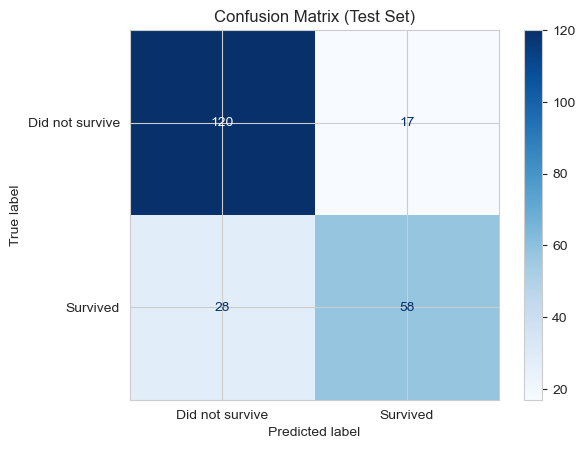


Accuracy:  0.798
Precision: 0.773
Recall:    0.674
F1 Score:  0.720

Full classification report:
                 precision    recall  f1-score   support

Did not survive       0.81      0.88      0.84       137
       Survived       0.77      0.67      0.72        86

       accuracy                           0.80       223
      macro avg       0.79      0.78      0.78       223
   weighted avg       0.80      0.80      0.80       223



In [68]:
# EXAMPLE
y_pred = split_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Did not survive', 'Survived'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()

print(f"\nAccuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.3f}")

print("\nFull classification report:")
print(classification_report(y_test, y_pred, target_names=['Did not survive', 'Survived']))


### Task 9
Using the model you trained in Task 8:
1. Compute and display its confusion matrix on the test set.
2. Print its accuracy, precision, recall, and F1 score.
3. Based on the confusion matrix, does this model make more false positives or more false negatives? Print your answer.

In [75]:
# TODO: confusion matrix for the Task 11 model on the test set
y_pred = split_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# TODO: print accuracy, precision, recall, F1
print(f"\nAccuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.3f}")

# TODO: print() whether there are more false positives or false negatives
if cm[0][1] < cm[1][1]:
    print("False Positives are more.")
else:
    print("False Negatives are more.")

Confusion Matrix:
 [[120  17]
 [ 28  58]]

Accuracy:  0.798
Precision: 0.773
Recall:    0.674
F1 Score:  0.720
False Positives are more.


## 11. The ROC Curve and AUC

### Theory
The **ROC curve** (Receiver Operating Characteristic) visualizes a classifier's performance **across all possible thresholds** at once, by plotting:
- **True Positive Rate** (= Recall) on the y-axis
- **False Positive Rate** ($=\frac{FP}{FP+TN}$) on the x-axis

A random-guessing classifier produces a diagonal line from `(0,0)` to `(1,1)`; a perfect classifier hugs the top-left corner. **AUC (Area Under the Curve)** summarizes the whole curve in a single number between 0 and 1:
- `AUC = 0.5` → no better than random guessing
- `AUC = 1.0` → perfect separation of classes
- `AUC` above roughly `0.8` is generally considered strong for real-world data

AUC is especially useful because, unlike accuracy, it doesn't depend on choosing a specific threshold.


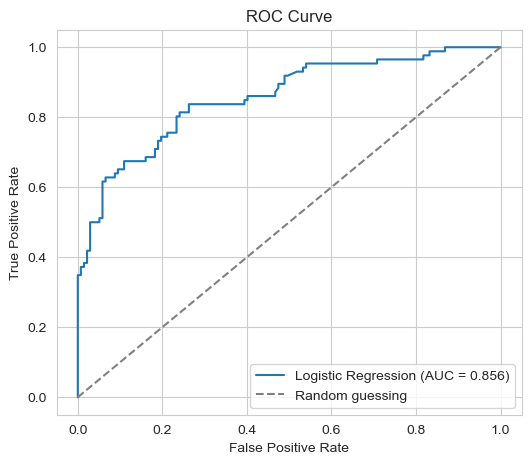

AUC: 0.8564


In [76]:
# EXAMPLE
y_pred_proba = split_model.predict_proba(X_test)[:, 1]   # probability of class 1

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print(f"AUC: {auc_score:.4f}")


### Task 10
Using your Task 8 model, plot its ROC curve and print its AUC score. Is this model doing meaningfully better than random guessing?

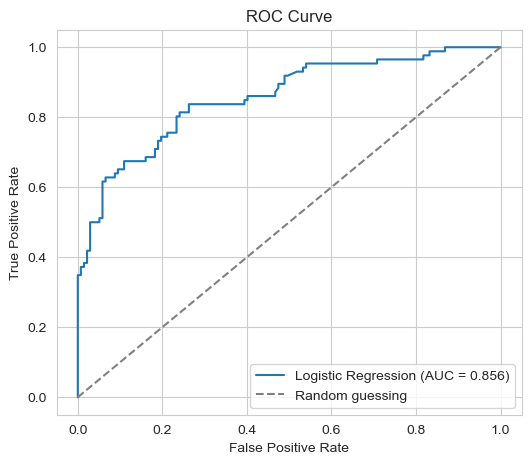

AUC: 0.8564


In [77]:
# TODO: plot ROC curve for the Task 11 model
y_pred_proba = split_model.predict_proba(X_test)[:, 1]   # probability of class 1

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print(f"AUC: {auc_score:.4f}")
# TODO: print AUC score and comment on whether it beats random guessing


## 12. Choosing the Classification Threshold

### Theory
Recall from Section 4 that we convert probabilities to classes using a threshold (default `0.5`). Changing the threshold changes the precision/recall trade-off:

- **Lowering** the threshold (e.g., to `0.3`) means the model predicts `1` more readily — this usually **increases recall** (catches more true positives) but **decreases precision** (more false positives creep in).
- **Raising** the threshold (e.g., to `0.7`) does the opposite — the model becomes more conservative about predicting `1`, typically **increasing precision** but **decreasing recall**.

The "right" threshold depends entirely on the real-world cost of each error type. For example, in a medical screening context, missing a true positive (a sick patient) is often far more costly than a false alarm — favoring a *lower* threshold and higher recall.


In [78]:
# EXAMPLE
y_pred_proba = split_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    y_pred_at_threshold = (y_pred_proba >= threshold).astype(int)
    precision = precision_score(y_test, y_pred_at_threshold)
    recall = recall_score(y_test, y_pred_at_threshold)
    print(f"Threshold={threshold}: Precision={precision:.3f}, Recall={recall:.3f}")


Threshold=0.3: Precision=0.664, Recall=0.826
Threshold=0.5: Precision=0.773, Recall=0.674
Threshold=0.7: Precision=0.852, Recall=0.535


### Task 11
Using your Task 8 model's predicted probabilities on the test set:
1. Compute precision and recall at thresholds `0.2`, `0.5`, and `0.8`.
2. Print all three sets of results.
3. In a `print()` statement, describe the trade-off you observe as the threshold increases.

In [80]:
# TODO: compute precision and recall at thresholds 0.2, 0.5, 0.8 for the Task 11 model
for threshold in [0.2, 0.5, 0.8]:
    y_pred_at_threshold = (y_pred_proba >= threshold).astype(int)
    precision = precision_score(y_test, y_pred_at_threshold)
    recall = recall_score(y_test, y_pred_at_threshold)
    print(f"Threshold={threshold}: Precision={precision:.3f}, Recall={recall:.3f}")

# TODO: print() the trade-off you observe
print("For threshold=0.2, as we decreased from 0.3, the precision has decrease, and for threshold=0.8, which we increased from 0.5, its precision has increased.")

Threshold=0.2: Precision=0.590, Recall=0.837
Threshold=0.5: Precision=0.773, Recall=0.674
Threshold=0.8: Precision=0.968, Recall=0.349
For threshold=0.2, as we decreased from 0.3, the precision has decrease, and for threshold=0.8, which we increased from 0.5, its precision has increased.


---
### Congratulations!
You've now built logistic regression from the ground up: the sigmoid function, the log-odds interpretation, the log loss cost function, gradient descent, using `scikit-learn` in practice, encoding categorical features, evaluating classifiers properly (beyond just accuracy), understanding the precision/recall trade-off, and applying regularization. Combined with the linear regression notebook, you now have the two foundational supervised learning algorithms that most other classification and regression techniques build on.